In [1]:
# import necessary libraries
from pathlib import Path
from contextlib import ExitStack
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import AsinhNorm

# Run from either the repository root or project/.
project_dir = Path.cwd() if Path("data/big_void_galaxy").is_dir() else Path.cwd() / "project"
data_dir = project_dir / "data/big_void_galaxy/2026-10-06"
calibration_dirs = [data_dir]  # Add folders containing this camera's flats/darks here.
use_synthetic_flats = True  # Use real flats automatically when they are available.
output_dir = project_dir / "calibration"
output_dir.mkdir(exist_ok=True)
row_chunk = 128  # Combine strips, rather than a multi-GB stack of full images.


def read_image(path):
    return fits.getdata(path).astype(np.float32)


def exposure(header):
    return float(header["EXPTIME"])


In [2]:
# load NGC 6503 fits
if not data_dir.is_dir():
    raise FileNotFoundError(data_dir)


def fits_paths(folder):
    return sorted(p for p in folder.rglob("*")
                  if p.is_file() and p.suffix.lower() in {".fit", ".fits", ".fts"})


science_headers = {p: fits.getheader(p) for p in fits_paths(data_dir)}
science_paths = [p for p, h in science_headers.items()
                 if "light" in h.get("IMAGETYP", "").lower()
                 and h.get("XBINNING") == h.get("YBINNING") == 1
                 and h.get("OBJECT", "").replace(" ", "").replace("-", "").upper() == "NGC6503"]
if not science_paths:
    raise ValueError("No NGC 6503 light frames found in the FITS headers.")
# Use the most common readout mode; the first exposure in each band has
# a different READOUTM label and cannot be assumed to share the same bias.
readout_mode = Counter(science_headers[p].get("READOUTM") for p in science_paths).most_common(1)[0][0]
reference = next(science_headers[p] for p in science_paths
                 if science_headers[p].get("READOUTM") == readout_mode)
shape = (reference["NAXIS2"], reference["NAXIS1"])

# Check geometry, camera/readout configuration, and temperature before combining.
configuration_keys = ("NAXIS1", "NAXIS2", "XBINNING", "YBINNING", "XORGSUBF",
                      "YORGSUBF", "INSTRUME", "TELESCOP", "READOUTM", "SET-TEMP")


def compatible(header):
    same_setup = all(header.get(k) == reference.get(k) for k in configuration_keys)
    return same_setup and abs(float(header["CCD-TEMP"]) - float(reference["CCD-TEMP"])) <= 0.5


for path in science_paths:
    if not compatible(science_headers[path]):
        print(f"Skipping science frame with unmatched detector/readout settings: {path.name}")
science_paths = [p for p in science_paths if compatible(science_headers[p])]
print(f"NGC 6503: {len(science_paths)} frames, shape {shape}")
for key, count in sorted(Counter((science_headers[p]["FILTER"], exposure(science_headers[p]))
                                 for p in science_paths).items()):
    print(f"  {key[0]}: {count} exposures of {key[1]:g} s")
# OBJECT is authoritative: two NGC-6503 filenames actually contain PGC 71538.


Skipping science frame with unmatched detector/readout settings: NGC-6503_LIGHT_g'_1x1_120.000secs_00000099.fit
Skipping science frame with unmatched detector/readout settings: NGC-6503_LIGHT_i'_1x1_180.000secs_00000135.fit
Skipping science frame with unmatched detector/readout settings: NGC-6503_LIGHT_r'_1x1_120.000secs_00000119.fit
NGC 6503: 28 frames, shape (8748, 11664)
  g': 10 exposures of 120 s
  i': 9 exposures of 180 s
  r': 9 exposures of 120 s


In [3]:
# load the flats, darks, and biases
calibration_headers = {p: fits.getheader(p) for folder in calibration_dirs for p in fits_paths(folder)}
bias_paths, dark_paths, flat_paths = [], [], []
for path, header in calibration_headers.items():
    kind = header.get("IMAGETYP", "").lower()
    if not any(word in kind for word in ("bias", "dark", "flat")):
        continue
    if not compatible(header):
        print(f"Skipping incompatible calibration: {path.name}")
        continue
    if "bias" in kind:
        bias_paths.append(path)
    elif "dark" in kind:
        dark_paths.append(path)
    elif "flat" in kind:
        flat_paths.append(path)
if not bias_paths:
    raise ValueError("At least one matching bias frame is required.")
if any(exposure(calibration_headers[p]) != 0 for p in bias_paths):
    raise ValueError("A bias frame has a nonzero exposure time.")
print(f"Matching calibration frames: {len(bias_paths)} bias, {len(dark_paths)} dark, {len(flat_paths)} flat")
if not dark_paths:
    print("Dark subtraction is intentionally omitted for this project.")
synthetic_mode = use_synthetic_flats and not flat_paths
if synthetic_mode:
    output_dir = project_dir / "calibration/synthetic_demo"
    output_dir.mkdir(parents=True, exist_ok=True)
    print("DEMO: generating synthetic flats. Resulting science images are demonstration products.")
elif not flat_paths:
    print("No matching flats: only bias correction is currently possible.")
# Pset 3/4 calibrations are from a different 1024 x 1024 detector; do not reuse them.


Matching calibration frames: 30 bias, 0 dark, 0 flat
Dark subtraction is intentionally omitted for this project.
DEMO: generating synthetic flats. Resulting science images are demonstration products.


In [4]:
# create a master flat, master bias
# Median combination rejects isolated outliers; retain native ADU units.
def median_combine(paths):
    combined = np.empty(shape, dtype=np.float32)
    with ExitStack() as stack:
        hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in paths]
        for y in range(0, shape[0], row_chunk):
            rows = slice(y, min(y + row_chunk, shape[0]))
            # section handles the unsigned FITS BZERO scaling without loading a full frame.
            strip = np.stack([h[0].section[rows, :].astype(np.float32) for h in hdus])
            combined[rows] = np.median(strip, axis=0, overwrite_input=True)
    return combined


def save_master(data, filename, kind, paths, unit="adu", **keywords):
    header = fits.Header()
    for key in configuration_keys + ("CCD-TEMP",):
        if key in reference:
            header[key] = reference[key]
    header["IMAGETYP"] = kind
    header["BUNIT"] = unit
    header["NCOMBINE"] = len(paths)
    header["SYNTHET"] = kind == "Master Flat" and synthetic_mode
    for key, value in keywords.items():
        header[key] = value
    header.add_history("Pixelwise median combination; float32 output.")
    for path in paths:
        header.add_history(f"Input: {path.name}")
    fits.writeto(output_dir / filename, data, header, overwrite=True)
    print(f"Saved {filename}: {len(paths)} inputs, median = {np.nanmedian(data):.6g} {unit}")


master_bias = median_combine(bias_paths)
save_master(master_bias, "master_bias.fit", "Master Bias", bias_paths, EXPTIME=0.0)

# Dark subtraction is intentionally omitted, as specified for this project.

# Make mock raw flats at the real detector size: bias + illumination * response
# + approximate photon/read noise (unit gain for simulation only).
# The artificial response includes vignetting, a gradient, and a dust shadow.
# These values exercise the pipeline; they do not measure this camera's response.
def synthetic_response(rows, band):
    x = np.linspace(-1, 1, shape[1], dtype=np.float32)[None, :]
    y = (2 * np.arange(rows.start, rows.stop, dtype=np.float32)
         / (shape[0] - 1) - 1)[:, None]
    strength = {"g'": 0.10, "r'": 0.08, "i'": 0.06}.get(band, 0.08)
    dust = np.exp(-((x - 0.25)**2 + (y + 0.15)**2) / (2 * 0.07**2))
    return 1 - strength * (x*x + y*y) + 0.02*x - 0.05*dust


if synthetic_mode:
    synthetic_dir = output_dir / "synthetic_inputs"
    synthetic_dir.mkdir(exist_ok=True)
    rng = np.random.default_rng(6503)
    for band in sorted({science_headers[p]["FILTER"] for p in science_paths}):
        safe_band = "".join(c for c in band if c.isalnum())
        for index, level in enumerate((18000, 24000, 30000), start=1):
            raw = np.empty(shape, dtype=np.uint16)
            for y in range(0, shape[0], row_chunk):
                rows = slice(y, min(y + row_chunk, shape[0]))
                signal = level * synthetic_response(rows, band)
                noise = rng.normal(size=signal.shape).astype(np.float32) * np.sqrt(signal + 25)
                raw[rows] = np.rint(np.clip(master_bias[rows] + signal + noise, 0, 65535)).astype(np.uint16)
            header = fits.Header()
            for key in configuration_keys + ("CCD-TEMP",):
                if key in reference:
                    header[key] = reference[key]
            header["IMAGETYP"] = "Flat Frame"
            header["FILTER"] = band
            header["EXPTIME"] = 1.0
            header["SYNTHET"] = True
            header["SIMLEVEL"] = level
            header.add_history("Synthetic demo: measured master bias + artificial response + noise.")
            path = synthetic_dir / f"synthetic_flat_{safe_band}_{index:02d}.fit"
            fits.writeto(path, raw, header, overwrite=True)
            flat_paths.append(path)
            calibration_headers[path] = header
            del raw
        print(f"Generated 3 synthetic {band} flats.")

# Normalize each flat before combining, separately for each optical filter.
flat_groups = defaultdict(list)
for path in flat_paths:
    flat_groups[calibration_headers[path]["FILTER"]].append(path)
master_flats = {}
for band, paths in sorted(flat_groups.items()):
    kept, scales = [], []
    for path in paths:
        raw = read_image(path)
        if not np.isfinite(raw).all() or np.max(raw) >= 65535:
            print(f"Rejecting nonfinite/saturated flat: {path.name}")
            continue
        raw -= master_bias
        scale = float(np.median(raw))
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError(f"Nonpositive flat signal: {path.name}")
        kept.append(path)
        scales.append(scale)
        del raw
    if not kept:
        raise ValueError(f"No usable flats for {band}.")
    # Combine the bias-subtracted, individually normalized flat strips.
    flat = np.empty(shape, dtype=np.float32)
    with ExitStack() as stack:
        hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in kept]
        for y in range(0, shape[0], row_chunk):
            rows = slice(y, min(y + row_chunk, shape[0]))
            strips = []
            for path, hdu, scale in zip(kept, hdus, scales):
                strip = hdu[0].section[rows, :].astype(np.float32) - master_bias[rows]
                strips.append(strip / scale)
            flat[rows] = np.median(np.stack(strips), axis=0)
    flat /= np.median(flat)
    flat[~np.isfinite(flat) | (flat <= 0)] = np.nan
    master_flats[band] = flat
    safe_band = "".join(c for c in band if c.isalnum())
    save_master(flat, f"master_flat_{safe_band}.fit", "Master Flat", kept,
                unit="relative", FILTER=band, BIASCOR=True,
                DARKCOR=False)

assert np.isfinite(master_bias).all()
# Independently verify a small patch against the original bias files.
with ExitStack() as stack:
    hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in bias_paths]
    expected = np.median(np.stack([h[0].section[:16, :16].astype(np.float32) for h in hdus]), axis=0)
np.testing.assert_array_equal(master_bias[:16, :16], expected)
print("Master-bias pixel check passed.")

# Check the recovered synthetic response against the known noiseless model.
if synthetic_mode:
    rows = slice(0, shape[0], 1)
    for band, flat in master_flats.items():
        # Sample the full field to keep the diagnostic lightweight.
        truth = np.stack([synthetic_response(slice(y, y + 1), band)[0, ::32]
                          for y in range(0, shape[0], 32)])
        truth /= np.median(truth)
        recovered = flat[::32, ::32]
        recovered = recovered / np.median(recovered)
        fractional_rms = np.sqrt(np.mean((recovered / truth - 1)**2))
        assert fractional_rms < 0.01, (band, fractional_rms)
        assert np.isclose(np.nanmedian(flat), 1, atol=1e-6)
        print(f"{band} synthetic-response recovery RMS: {100*fractional_rms:.3f}%")


Saved master_bias.fit: 30 inputs, median = 317 adu
Generated 3 synthetic g' flats.
Generated 3 synthetic i' flats.
Generated 3 synthetic r' flats.
Saved master_flat_g.fit: 3 inputs, median = 1 relative
Saved master_flat_i.fit: 3 inputs, median = 1 relative
Saved master_flat_r.fit: 3 inputs, median = 1 relative
Master-bias pixel check passed.
g' synthetic-response recovery RMS: 0.454%
i' synthetic-response recovery RMS: 0.447%
r' synthetic-response recovery RMS: 0.449%


In [5]:
# Calibrate the ngc frames with these flats and biases
# Bias is in ADU; flat is dimensionless. Dark subtraction is omitted by design.
def calibrate_frame(path, save=False):
    header = fits.getheader(path)
    if not compatible(header):
        raise ValueError(f"Incompatible science frame: {path}")
    corrected = read_image(path) - master_bias
    flat = master_flats.get(header["FILTER"])
    if flat is not None:
        corrected /= flat  # Invalid flat pixels propagate as NaN.
    header["BUNIT"] = "adu"
    header["BIASCOR"] = True
    header["DARKCOR"] = False
    header["FLATCOR"] = flat is not None
    header["SYNTHET"] = synthetic_mode and flat is not None
    if header["SYNTHET"]:
        header.add_history("DEMO ONLY: corrected using an artificial flat, not a measured response.")
    header.add_history("Correction: (raw - master_bias) / matching flat, if available.")
    header.add_history("Dark intentionally omitted; flat division only when FLATCOR is true.")
    header.add_history(f"Master bias: {output_dir.name}/master_bias.fit")
    if flat is not None:
        safe_band = "".join(c for c in header["FILTER"] if c.isalnum())
        header.add_history(f"Master flat: {output_dir.name}/master_flat_{safe_band}.fit")
    if save:
        fits.writeto(output_dir / f"{path.stem}_calibrated.fit", corrected, header, overwrite=True)
    return corrected, header


# Save one representative g-band exposure now. Enable the loop for all matching frames
# when the available calibration is sufficient (about 11 GB of float32 output).
run_all_science = False
example_path = next(p for p in science_paths if science_headers[p]["FILTER"] == "g'")
if run_all_science:
    for path in science_paths:
        corrected, _ = calibrate_frame(path, save=True)
        del corrected
calibrated_image, calibrated_header = calibrate_frame(example_path, save=True)
print(f"Saved example: {example_path.stem}_calibrated.fit")
print({k: calibrated_header[k] for k in ("BIASCOR", "DARKCOR", "FLATCOR", "SYNTHET")})
if not calibrated_header["FLATCOR"]:
    print("Bias-only correction; flat-field correction awaits project flats. Darks are not required.")
if synthetic_mode:
    print(f"Synthetic-flat demonstration products saved in {output_dir}.")


Saved example: NGC-6503_LIGHT_g'_1x1_120.000secs_00000100_calibrated.fit
{'BIASCOR': True, 'DARKCOR': False, 'FLATCOR': True, 'SYNTHET': True}
Synthetic-flat demonstration products saved in /Users/rohan/Developer Folder/GitHub/12.410-code/project/calibration/synthetic_demo.


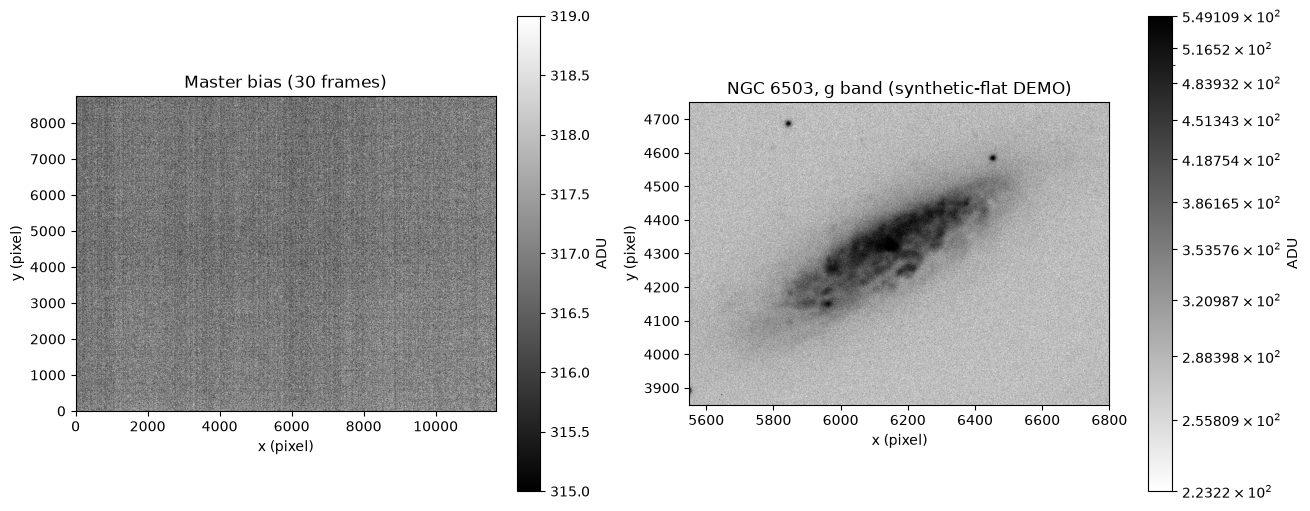

Saved FITS dimensions, flags, and science-pixel checks passed.


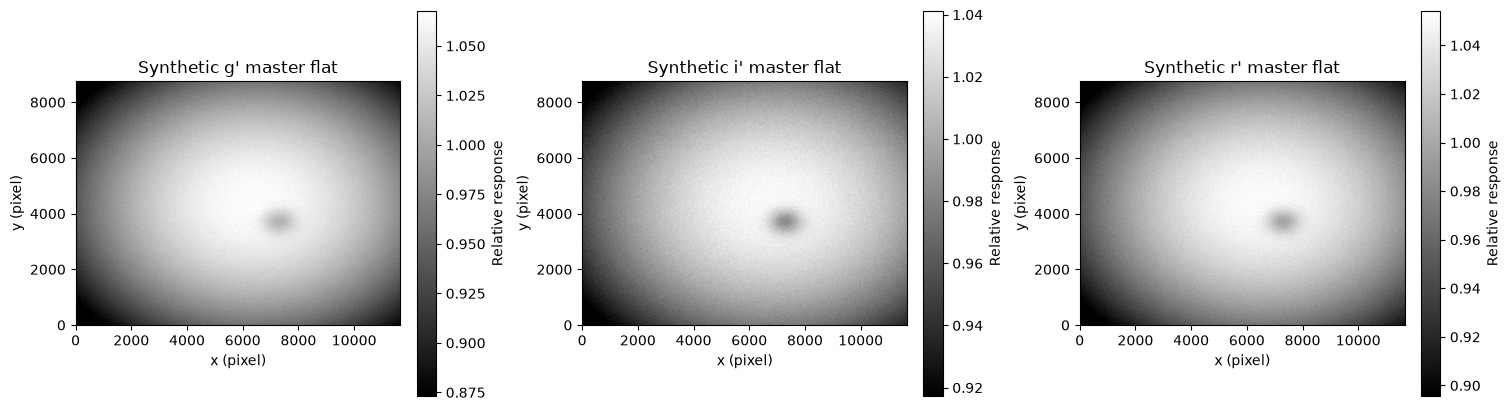

In [6]:
# Display a calibrated NGC 6503 image
# Use the galaxy crop identified in galactic_imaging.ipynb; never bin the saved data.
ymin, ymax, xmin, xmax = 3850, 4750, 5550, 6800
crop = calibrated_image[ymin:ymax, xmin:xmax]
lo, hi = np.nanpercentile(crop, [1, 99.7])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
bias_preview = master_bias[::8, ::8]
blo, bhi = np.percentile(bias_preview, [1, 99])
im = axes[0].imshow(bias_preview, origin="lower", cmap="gray", vmin=blo, vmax=bhi,
                    extent=(0, shape[1], 0, shape[0]))
axes[0].set(title=f"Master bias ({len(bias_paths)} frames)", xlabel="x (pixel)", ylabel="y (pixel)")
fig.colorbar(im, ax=axes[0], label="ADU")
im = axes[1].imshow(crop, origin="lower", cmap="gray_r",
                    norm=AsinhNorm(linear_width=(hi - lo) / 10, vmin=lo, vmax=hi),
                    extent=(xmin, xmax, ymin, ymax))
status = "synthetic-flat DEMO" if synthetic_mode else ("bias only" if not master_flats else "bias + flat")
axes[1].set(title=f"NGC 6503, g band ({status})", xlabel="x (pixel)", ylabel="y (pixel)")
fig.colorbar(im, ax=axes[1], label="ADU")
plt.show()

# Confirm saved products preserve dimensions and correction flags.
with fits.open(output_dir / "master_bias.fit", memmap=False) as hdu:
    assert hdu[0].shape == shape and hdu[0].header["NCOMBINE"] == len(bias_paths)
with fits.open(output_dir / f"{example_path.stem}_calibrated.fit", memmap=False) as hdu:
    assert hdu[0].shape == shape and hdu[0].header["BIASCOR"]
    np.testing.assert_array_equal(hdu[0].section[ymin:ymax, xmin:xmax], crop)
with fits.open(example_path, memmap=False) as hdu:
    expected = hdu[0].section[ymin:ymax, xmin:xmax].astype(np.float32) - master_bias[ymin:ymax, xmin:xmax]
example_flat = master_flats.get(calibrated_header["FILTER"])
if example_flat is not None:
    expected /= example_flat[ymin:ymax, xmin:xmax]
np.testing.assert_array_equal(crop, expected)
print("Saved FITS dimensions, flags, and science-pixel checks passed.")

if master_flats:
    fig, axes = plt.subplots(1, len(master_flats), figsize=(5 * len(master_flats), 4),
                             squeeze=False, layout="constrained")
    for ax, (band, flat) in zip(axes[0], sorted(master_flats.items())):
        preview = flat[::16, ::16]
        lo, hi = np.nanpercentile(preview, [1, 99])
        im = ax.imshow(preview, origin="lower", cmap="gray", vmin=lo, vmax=hi,
                       extent=(0, shape[1], 0, shape[0]))
        label = "Synthetic" if synthetic_mode else "Measured"
        ax.set(title=f"{label} {band} master flat", xlabel="x (pixel)", ylabel="y (pixel)")
        fig.colorbar(im, ax=ax, label="Relative response")
    plt.show()


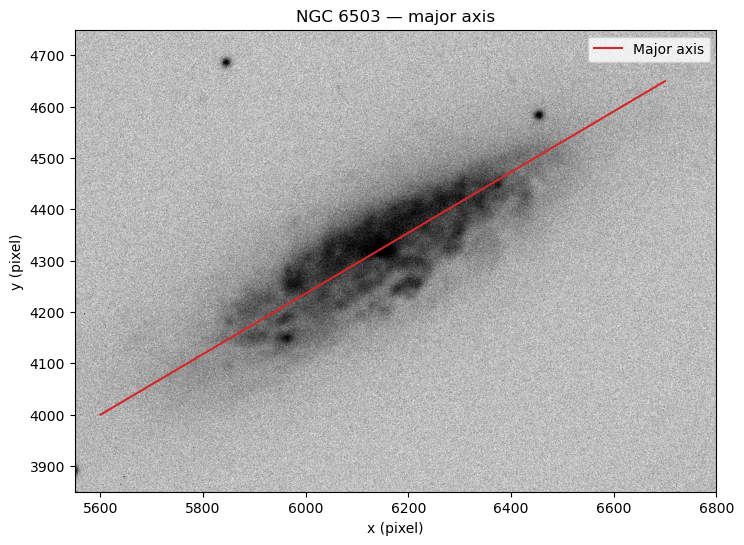

In [2]:
# Create a `construction line` along the major axis of the galaxy

axis_ends = np.array([[5600, 4000], [6700, 4650]])
axis_vector = axis_ends[1] - axis_ends[0]
axis_length = np.linalg.norm(axis_vector)
lo, hi = np.nanpercentile(crop, [1, 99.7])
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(crop, origin="lower", cmap="gray_r", extent=(xmin, xmax, ymin, ymax),
          norm=AsinhNorm(linear_width=(hi - lo) / 10, vmin=lo, vmax=hi))
ax.plot(*axis_ends.T, color="tab:red", label="Major axis")
ax.set(xlabel="x (pixel)", ylabel="y (pixel)", title="NGC 6503 — major axis")
ax.legend()
plt.show()


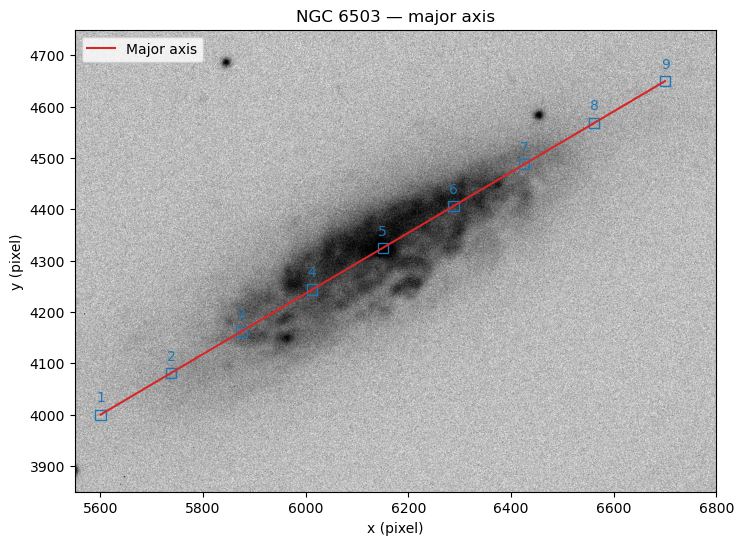

Box centers (x, y):
 [[5600 4000]
 [5738 4081]
 [5875 4162]
 [6012 4244]
 [6150 4325]
 [6288 4406]
 [6425 4488]
 [6562 4569]
 [6700 4650]]


In [3]:
# Define 9 squares along this line, roughly equidistant from each other, 
# with the outermost being slightly past the visible arms of the galaxy (about (5600, 4000) and (6700, 4650)).
# The size of each square should be something like 20 x 20.

from matplotlib.patches import Rectangle

box_size = 20
box_centers = np.rint(np.linspace(*axis_ends, 9)).astype(int)
distance = (box_centers - axis_ends.mean(axis=0)) @ (axis_vector / axis_length)

# Show the same image and line, now with the nine measurement boxes.
for number, (x, y) in enumerate(box_centers, 1):
    ax.add_patch(Rectangle((x - box_size / 2, y - box_size / 2), box_size, box_size,
                           fill=False, edgecolor="tab:blue"))
    ax.text(x, y + 25, str(number), color="tab:blue", ha="center")
display(fig)
print("Box centers (x, y):\n", box_centers)


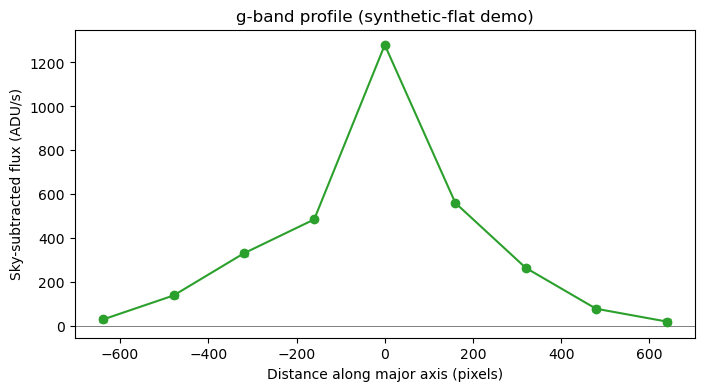

1-sigma errors use local sky-box scatter; source shot noise is omitted (gain unknown).


In [4]:
# Compute the flux along each square and plot the results. Use the g-band calibrated image for this analysis. Have error bars of one sigma.

# Estimate local sky/noise from equal-sized boxes on both sides of the galaxy.
# Without a measured gain, errors include background noise but omit source shot noise.
normal = np.array([-axis_vector[1], axis_vector[0]]) / axis_length
sky_offsets = np.r_[-np.arange(350, 951, 50), np.arange(350, 951, 50)]


def box_pixels(image, center):
    x, y = np.rint(center).astype(int)
    half = box_size // 2
    if not (half <= x <= image.shape[1] - half and half <= y <= image.shape[0] - half):
        raise ValueError("Measurement box lies outside the image.")
    return image[y - half:y + half, x - half:x + half]


def measure_profile(image, header):
    flux, error = [], []
    gain = header.get("EGAIN", header.get("GAIN"))  # electrons per ADU, if recorded
    for center in box_centers:
        sky_sums = np.array([np.sum(box_pixels(image, center + offset * normal))
                             for offset in sky_offsets])
        sky_sums = sky_sums[np.isfinite(sky_sums)]
        if len(sky_sums) < 5:
            raise ValueError("Too few valid sky boxes.")
        sky = np.median(sky_sums)
        scatter = 1.4826 * np.median(np.abs(sky_sums - sky))
        if scatter > 0:
            sky_sums = sky_sums[np.abs(sky_sums - sky) < 3 * scatter]
        sky, scatter = np.median(sky_sums), np.std(sky_sums, ddof=1)
        signal = np.sum(box_pixels(image, center)) - sky
        # Noise of an aperture sum plus uncertainty in its median sky estimate.
        variance = scatter**2 * (1 + np.pi / (2 * len(sky_sums)))
        if gain is not None and float(gain) > 0:
            variance += max(signal, 0) / float(gain)
        flux.append(signal / exposure(header))
        error.append(np.sqrt(variance) / exposure(header))
    return np.array(flux), np.array(error)


profiles = {"g": measure_profile(calibrated_image, calibrated_header)}
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(distance, *profiles["g"], fmt="o-", capsize=3, color="tab:green")
ax.axhline(0, color="gray", lw=0.7)
ax.set(xlabel="Distance along major axis (pixels)", ylabel="Sky-subtracted flux (ADU/s)",
       title="g-band profile (synthetic-flat demo)" if synthetic_mode else "g-band profile")
plt.show()
if not any(k in calibrated_header for k in ("EGAIN", "GAIN")):
    print("1-sigma errors use local sky-box scatter; source shot noise is omitted (gain unknown).")


r: NGC-6503_LIGHT_r'_1x1_120.000secs_00000120.fit


i: NGC-6503_LIGHT_i'_1x1_180.000secs_00000136.fit


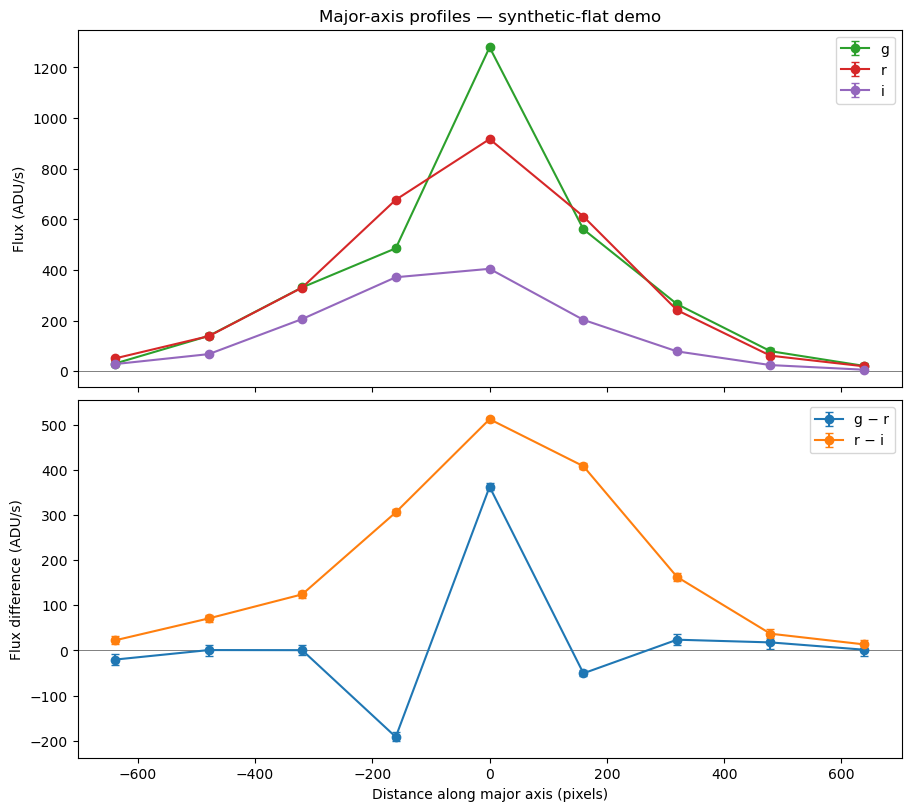

In [5]:
# Compute the same as the above cell for the r-band and i-band calibrated images. Plot both of these as well as the color flux of each.

for band in ("r", "i"):
    path = next(p for p in science_paths if science_headers[p]["FILTER"] == f"{band}'")
    band_image, band_header = calibrate_frame(path, save=True)
    profiles[band] = measure_profile(band_image, band_header)
    print(f"{band}: {path.name}")
    del band_image

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True, layout="constrained")
for band, color in zip(("g", "r", "i"), ("tab:green", "tab:red", "tab:purple")):
    axes[0].errorbar(distance, *profiles[band], fmt="o-", capsize=3, color=color, label=band)

# These are flux differences, as requested; no magnitude/zero-point conversion.
color_profiles = {}
for first, second in (("g", "r"), ("r", "i")):
    flux1, error1 = profiles[first]
    flux2, error2 = profiles[second]
    difference = flux1 - flux2
    uncertainty = np.hypot(error1, error2)  # Treat the two band errors as independent.
    color_profiles[f"{first}-{second}"] = (difference, uncertainty)
    axes[1].errorbar(distance, difference, yerr=uncertainty, fmt="o-", capsize=3,
                     label=f"{first} − {second}")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.7)
    ax.set_ylabel("Flux (ADU/s)")
    ax.legend()
axes[0].set_title("Major-axis profiles" + (" — synthetic-flat demo" if synthetic_mode else ""))
axes[1].set(xlabel="Distance along major axis (pixels)", ylabel="Flux difference (ADU/s)")
plt.show()
